In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
from torch_geometric.nn import SAGEConv

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.GroupNorm(8, out_channels),
            nn.GELU()
        )

    def forward(self, x):
        return self.block(x)

class ShipGeometryEncoder(nn.Module):

    def __init__(self, latent_dim=512):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1, 32),       # 256 -> 128
            ConvBlock(32, 64),      # 128 -> 64
            ConvBlock(64, 128),     # 64 -> 32
            ConvBlock(128, 256),    # 32 -> 16
            ConvBlock(256, 512)     # 16 -> 8
        )
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(
            512 * 8 * 8,
            latent_dim
        )

    def forward(self, x):
        feature_map = self.features(x)
        z = self.fc(
            self.flatten(feature_map)
        )
        return z, feature_map

class RoomGraphEncoder(nn.Module):

    def __init__(self, input_dim=8, hidden_dim=64, output_dim=128):
        super().__init__()
        self.conv1 = SAGEConv(input_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, output_dim)

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        return x

class CrossAttention(nn.Module):

    def __init__(self, query_dim, context_dim, hidden_dim):
        super().__init__()
        self.query = nn.Linear(query_dim, hidden_dim)
        self.key = nn.Linear(context_dim, hidden_dim)
        self.value = nn.Linear(context_dim, hidden_dim)
        self.output = nn.Linear(hidden_dim, query_dim)

    def forward(self, x_query, x_context):
        # Project inputs
        Q = self.query(x_query)
        K = self.key(x_context)
        V = self.value(x_context)
        # Calculate attention scores
        scores = torch.matmul(Q, K.transpose(-2, -1))
        scores = scores / math.sqrt(K.shape[-1])
        # Normalize attention scores
        attention = torch.softmax(scores, dim=-1)
        # Weighted sum of values
        out = torch.matmul(attention, V)
        return self.output(out)

class ImageGraphFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.cross_attention = CrossAttention(
            query_dim=512,
            context_dim=128,
            hidden_dim=256
        )

        self.norm = nn.LayerNorm(512)

    def forward(self, image_features, graph_features):

        # Image: [B, 512, 8, 8]
        # Graph: [B, 7, 128]

        B, C, H, W = image_features.shape

        # Convert image into sequence
        image = image_features.flatten(2).transpose(1, 2)

        # Cross attention
        fused = self.cross_attention(image, graph_features)

        # Residual connection + normalization
        fused = self.norm(image + fused)

        # Restore spatial dimensions
        fused = fused.transpose(1, 2).reshape(B, C, H, W)

        return fused




/home/dominik/miniconda3/envs/nlp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
import torch
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv

# Node features:
# [area, mass, cabin, corridor, kitchen, lounge, engine, storage]
x = torch.tensor([
    [0.50, 0.17, 1, 0, 0, 0, 0, 0],  # 0: Cabin 1
    [0.67, 0.25, 0, 1, 0, 0, 0, 0],  # 1: Corridor
    [0.47, 0.16, 1, 0, 0, 0, 0, 0],  # 2: Cabin 2
    [0.60, 0.38, 0, 0, 1, 0, 0, 0],  # 3: Kitchen
    [1.00, 0.42, 0, 0, 0, 1, 0, 0],  # 4: Lounge
    [0.83, 1.00, 0, 0, 0, 0, 1, 0],  # 5: Engine room
    [0.40, 0.21, 0, 0, 0, 0, 0, 1],  # 6: Storage
], dtype=torch.float)


# Define edges (bidirectional)
edge_index = torch.tensor([
    [0, 1, 1, 1, 1, 2, 3, 4, 4, 5, 5, 6],
    [1, 0, 2, 3, 4, 1, 1, 1, 5, 4, 6, 5]
], dtype=torch.long)

# Create PyG graph
graph = Data(
    x=x,
    edge_index=edge_index
)

model = RoomGraphEncoder(input_dim=8, hidden_dim=64, output_dim=128)
graph_features = model(graph.x, graph.edge_index)

In [ ]:
x = torch.rand(1, 1, 256, 256)
encoder = ShipGeometryEncoder(latent_dim=512)
encoder.eval()
with torch.no_grad():
    z, image_features = encoder(x)
    
print("Feature map:", image_features.shape)

Feature map: torch.Size([1, 512, 8, 8])


### Fuse features with cross-attention

In [ ]:
fusion = ImageGraphFusion()
output = fusion(image_features, graph_features)
print(output.shape)
# [1, 512, 8, 8]

torch.Size([1, 512, 8, 8])


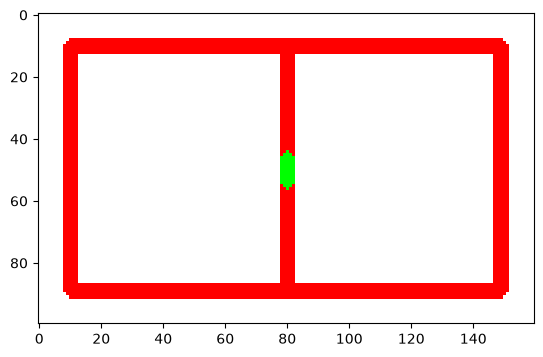

In [6]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def make_two_room_floorplan():
    image = np.full((100, 160, 3), 255, dtype=np.uint8)  # white, RGB

    # Red outer boundary and divider; green doorway.
    cv2.rectangle(image, (10, 10), (149, 89), (255, 0, 0), thickness=4)
    cv2.line(image, (80, 12), (80, 88), (255, 0, 0), thickness=4)
    cv2.line(image, (80, 46), (80, 54), (0, 255, 0), thickness=4)

    return Image.fromarray(image)

img = make_two_room_floorplan()
plt.imshow(img)
